# Dar_008 — P1 calibrated imagery and surface-change context
**D15:** NAC calibrated CDR left/right images; **D27:** one 32-bit ShadowCam calibrated
map COG; **D33:** published new-crater shapefile, README and before/after identifiers.

Explore numeric support, masks, brightness distributions, image coverage, source quality
and crater size/location distributions. No visual boulder detector, ice classifier or
surface-hazard predictor is implied.

In [3]:
from pathlib import Path
import sys, json, io, re, zipfile
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p/'outline.md').is_file() and (p/'notebooks').is_dir())
sys.path[:0] = [str(ROOT / "env_algo_task/EDA/shared"), str(ROOT / "env_algo_task/EDA/Moon/Stage3_Requirements"),str(ROOT)]
DATA = ROOT/'env_algo_task/data'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from environment_workflow import LocalRun as Run, latest_completed_run
from notebooks.shared.inspection import verify_run, check_input
from research_p1_readers import (pilot_files, pin_source, read_pds4, pds4_chunks,
    pds4_definition, pds4_image, dose_profiles, pds3_number)
import research_p1_readers
def savefig(run, fig, name):
    fig.savefig(run.path(name+'.png'),dpi=140,bbox_inches='tight')
    display(fig); plt.close(fig)
def save_findings(run, findings):
    run.path('findings.json').write_text(json.dumps(findings,indent=2,default=str),encoding='utf-8')
    display(Markdown('**Executed findings**')); display(findings)
def pin(run, path): return pin_source(run, path)
def short(region): return region.split('_',2)[-1].replace('_',' ')

## Sampling and unit holds
NAC uses its PDS4 signed-LSB array offset, scale and special values. Every eighth native
row/column is a systematic sample, not an averaged image or a representative terrain sample.
ShadowCam uses every eighth native pixel with nodata masked before any display stretch;
32-bit floats alone do not establish radiance units. Missing unit evidence remains a hold.
NAC CDRs are not assumed map-projected. The ShadowCam pilot is north-polar, not one of
our seven south-polar regions; no unsupported PSR/terrain overlay is made. Crater rates
cannot be calculated without search-effort/area and observation-time brackets.

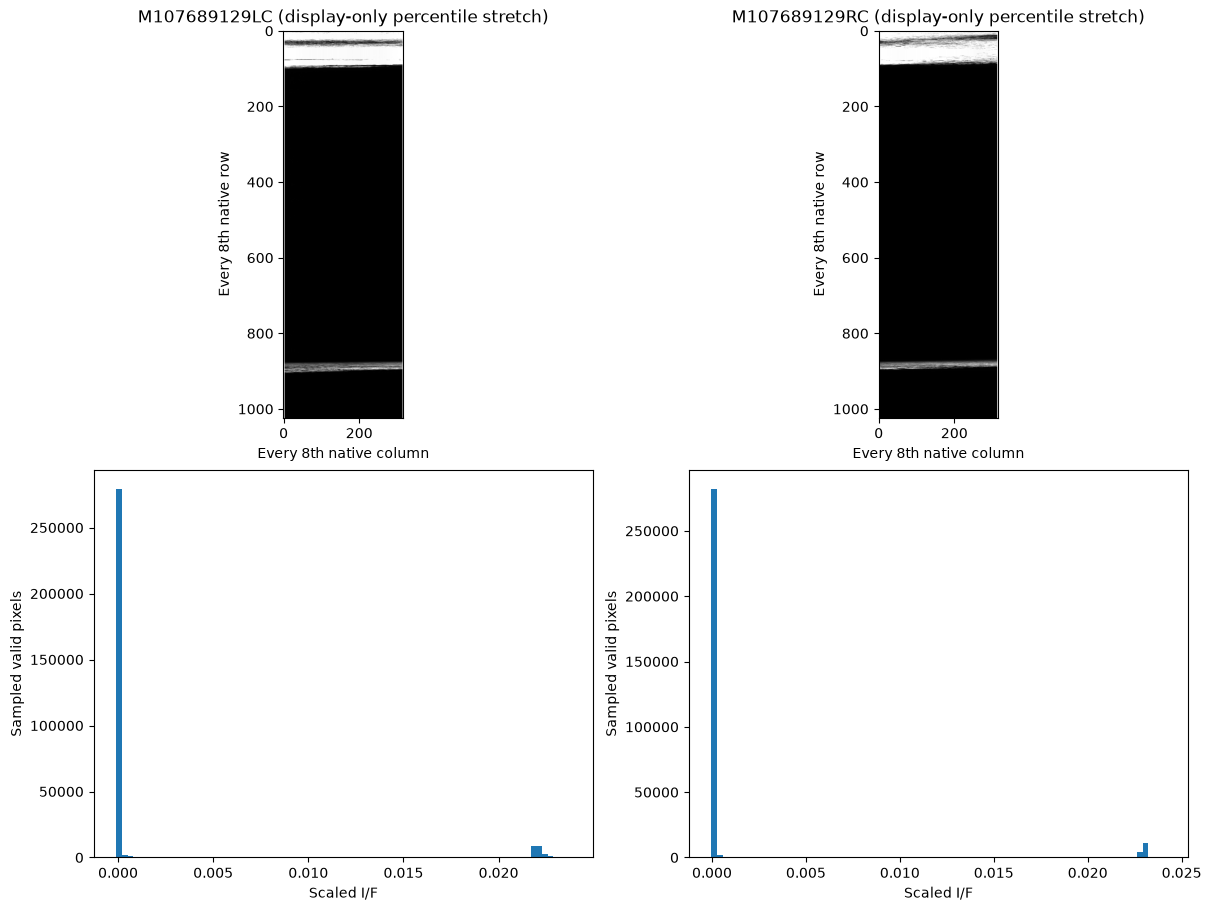

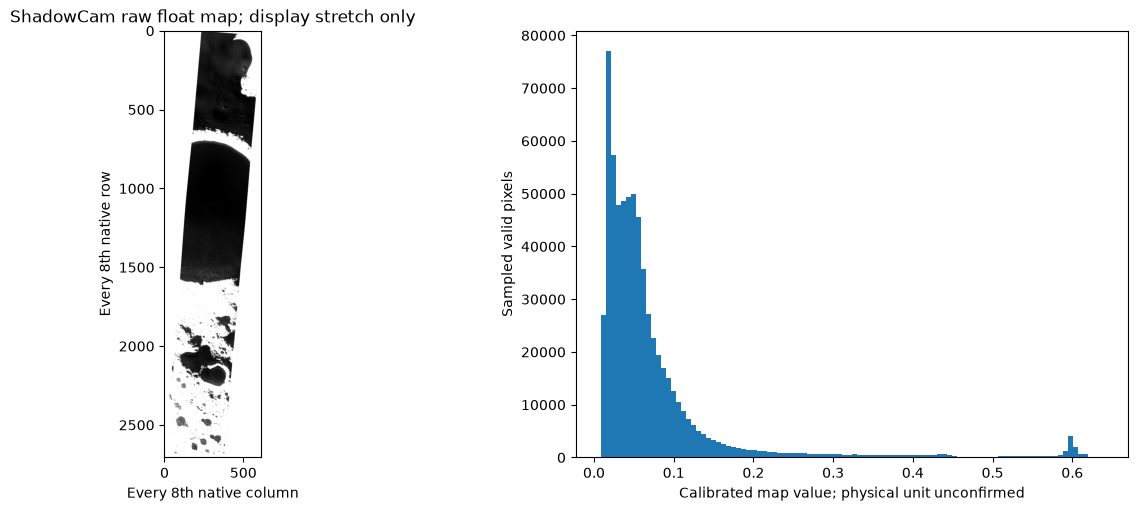

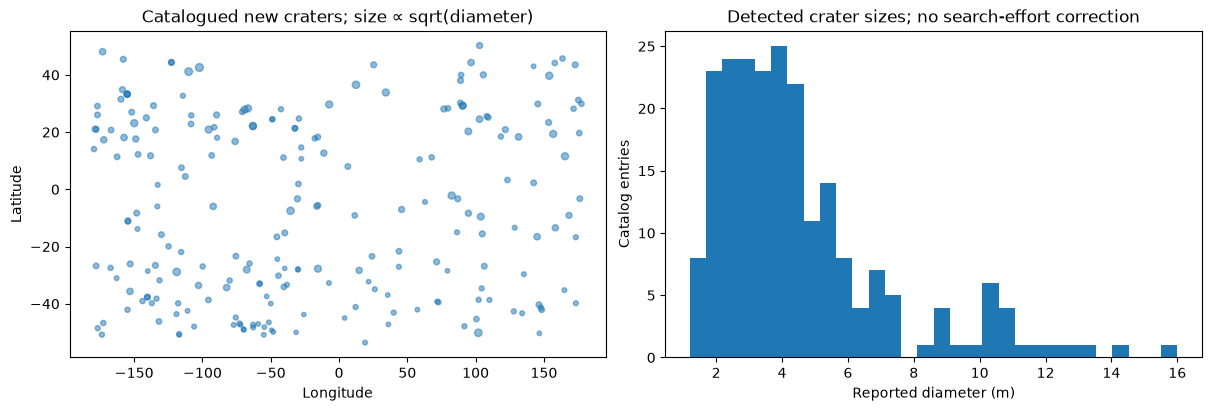

,lat,lon,before_img,after_img,diam_m
0,-48.27030,-62.8600,M173342916R,M1149900109L,2.5
1,12.21420,-147.1520,M1104524015L,M1150477887L,4.2
2,-4.39841,62.9124,M1105510067R,M1120825960R,2.2
3,-13.86700,-147.5840,M136152712L,M151487943R,2.2
4,-24.41200,-45.1590,M1099152576L,M1129788676L,1.8


**Executed findings**

{'NAC_images': 2,
 'NAC_quality_ids': ['2', '2'],
 'ShadowCam_center_latitude': 81.41240171575654,
 'ShadowCam_unit_status': 'unconfirmed',
 'crater_catalog_entries': 222,
 'crater_diameter_m_quantiles': {0.1: 1.9100000000000001,
  0.5: 3.8,
  0.9: 8.660000000000002},
 'holds': ['No south-polar ShadowCam/SDEM overlap for this pilot',
  'NAC map projection not established',
  'No crater formation dates from image IDs alone',
  'No impact probability, boulder hazard or ice inference']}

Completed: C:\Darrel\Self-Projects\1 group proj\NASA-Space-Apps-Challenge-2026\env_algo_task\data\processed\analysis\dar_008_research_imagery\20261109T151358049922Z_58a88b


In [4]:
import rasterio
from rasterio.enums import Resampling
from rasterio.windows import Window
import shapefile
from pyproj import Transformer
from notebooks.shared.processing import MOON_GEOGRAPHIC
with Run(ROOT,'analysis/dar_008_research_imagery',{'datasets':['D15','D27','D33'],'native_pixel_stride':8},'Moon/Dar_008_research_imagery_change.ipynb') as run:
    run.input(Path(research_p1_readers.__file__))
    image_rows=[];fig,axes=plt.subplots(2,2,figsize=(12,9),layout='constrained')
    for col,path in enumerate(pilot_files(DATA,'D15','.img')):
        label=path.with_suffix('.xml');pin(run,path);pin(run,label)
        values,meta=pds4_image(label,path,stride=8);finite=values[np.isfinite(values)]
        root=__import__('xml.etree.ElementTree',fromlist=['parse']).parse(label).getroot()
        quality=[e.text for e in root.iter() if e.tag.split('}')[-1]=='data_quality_id']
        image_rows.append({'dataset':'D15','product':path.stem,**meta,'quality_id':quality[0] if len(quality)==1 else None,
            'median':np.median(finite),'q10':np.quantile(finite,.1),'q90':np.quantile(finite,.9)})
        low,high=np.quantile(finite,[.01,.99]);axes[0,col].imshow(values,cmap='gray',vmin=low,vmax=high)
        axes[0,col].set(title=path.stem+' (display-only percentile stretch)',xlabel='Every 8th native column',ylabel='Every 8th native row')
        axes[1,col].hist(finite,bins=80);axes[1,col].set(xlabel=meta['unit'],ylabel='Sampled valid pixels')
    savefig(run,fig,'nac_calibrated_pixel_support')
    path=pilot_files(DATA,'D27','.tif')[0];label=path.with_suffix('.xml');pin(run,path);pin(run,label)
    with rasterio.open(path) as src:
        if src.dtypes!=('float32',):raise ValueError('ShadowCam science map must be float32')
        # Read native blocks, selecting a fixed global lattice; no overview resampling.
        pieces=[]
        for top in range(0,src.height,256):
            block=src.read(1,window=Window(0,top,src.width,min(256,src.height-top)),masked=True).astype(float).filled(np.nan)
            pieces.append(block[::8,::8]*src.scales[0]+src.offsets[0])
        shadow=np.vstack(pieces);finite=shadow[np.isfinite(shadow)]
        transform=Transformer.from_crs(src.crs,MOON_GEOGRAPHIC,always_xy=True)
        cx,cy=src.transform*(src.width/2,src.height/2);lon,lat=transform.transform(cx,cy)
        shadow_meta={'native_shape':src.shape,'native_resolution_m':src.res,'nodata':src.nodata,'unit':src.units[0],
            'center_lon':lon,'center_lat':lat,'physical_unit_status':'documented' if src.units[0] else 'unconfirmed',
            'sampled_pixels':shadow.size,'valid_sampled_pixels':len(finite),'median':np.median(finite)}
        run.path('shadowcam_grid_and_unit_hold.json').write_text(json.dumps(shadow_meta,indent=2),encoding='utf-8')
    fig,axes=plt.subplots(1,2,figsize=(12,5),layout='constrained')
    low,high=np.quantile(finite,[.01,.99]);axes[0].imshow(shadow,cmap='gray',vmin=low,vmax=high)
    axes[0].set(title='ShadowCam raw float map; display stretch only',xlabel='Every 8th native column',ylabel='Every 8th native row')
    axes[1].hist(finite,bins=100);axes[1].set(xlabel=shadow_meta['unit'] or 'Calibrated map value; physical unit unconfirmed',ylabel='Sampled valid pixels')
    savefig(run,fig,'shadowcam_numeric_support');pd.DataFrame(image_rows).to_csv(run.path('nac_pixel_quality_summary.csv'),index=False)
    archive=pilot_files(DATA,'D33','.zip')[0];pin(run,archive)
    with zipfile.ZipFile(archive) as z:
        stem='GLOBAL_NEW_CRATERS_180'
        reader=shapefile.Reader(shp=io.BytesIO(z.read(stem+'.SHP')),shx=io.BytesIO(z.read(stem+'.SHX')),dbf=io.BytesIO(z.read(stem+'.DBF')))
        craters=pd.DataFrame([r.as_dict() for r in reader.records()]);points=np.array([s.points[0] for s in reader.shapes()])
        if not np.allclose(points,craters[['lon','lat']],atol=1e-6):raise ValueError('Crater geometry/attribute mismatch')
        run.path('source_crater_readme.txt').write_bytes(z.read('GLOBAL_NEW_CRATERS_README.TXT'))
        run.path('source_crater_crs.prj').write_bytes(z.read(stem+'.PRJ'))
    if not craters.lat.between(-90,90).all() or not craters.lon.between(-180,180).all() or not craters.diam_m.gt(0).all():raise ValueError('Invalid crater locations/diameters')
    craters.to_csv(run.path('new_crater_catalog.csv'),index=False)
    fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
    axes[0].scatter(craters.lon,craters.lat,s=np.sqrt(craters.diam_m)*8,alpha=.5);axes[0].set(xlabel='Longitude',ylabel='Latitude',title='Catalogued new craters; size ∝ sqrt(diameter)')
    axes[1].hist(craters.diam_m,bins=30);axes[1].set(xlabel='Reported diameter (m)',ylabel='Catalog entries',title='Detected crater sizes; no search-effort correction')
    savefig(run,fig,'new_crater_context');display(craters.head())
    save_findings(run,{'NAC_images':len(image_rows),'NAC_quality_ids':[r['quality_id'] for r in image_rows],
        'ShadowCam_center_latitude':lat,'ShadowCam_unit_status':shadow_meta['physical_unit_status'],'crater_catalog_entries':len(craters),
        'crater_diameter_m_quantiles':craters.diam_m.quantile([.1,.5,.9]).to_dict(),
        'holds':['No south-polar ShadowCam/SDEM overlap for this pilot','NAC map projection not established',
                 'No crater formation dates from image IDs alone','No impact probability, boulder hazard or ice inference']})
OUT=run.directory;print('Completed:',OUT)

## Stage 3 role
Use numeric masks, quality flags and footprint/unit holds to decide whether imagery can
support a later inspection question. Before/after image IDs are a traceable route to dated
brackets, not dates themselves. A low-brightness pixel is not low terrain, and image texture
or raw crater density is not equipment risk. Scene selection, co-registration, calibration
and search-effort evidence remain necessary for the originally proposed site-level joins.